# XGBoost: how many V columns to keep?

The V columns (V1 to V339) come in blocks that share the same missing pattern, and inside a block many columns are
near copies of each other. The group's proposal (`config/features.yaml`, built by `src/data_profile.py`) prunes
them like this:

1. Group V columns by identical missing count on the training rows.
2. Inside each group, go through the columns from most to fewest distinct values, and drop a column if its
   |Pearson r| with a column already kept is above a threshold **r**. The proposal uses r = 0.9.

This notebook checks how much that choice of r matters for XGBoost. Everything else is held fixed:

- **Features:** all non-V raw columns plus all engineered `fe_` columns (the `S3_all` set from
  `notebooks/xgboost.ipynb`), plus whichever V columns survive pruning at threshold r.
- **Model:** the best tuned config from `notebooks/xgboost.ipynb`, read from `results/log.csv`.
- **Thresholds:** r = 0.75, 0.80, 0.85, 0.90, 0.95 and 1.00 (1.00 keeps every V column).
- **Validation:** the same 4 expanding-window CV folds inside the training block, seeds 0, 1 and 2.

Two choices worth knowing about:

- **Pruning is redone on each fold's own training rows.** The proposal's list was built on the whole training
  block, which includes the later folds' validation months. It uses no labels, so that's a small leak, but here
  the kept list for fold k only looks at fold k's training rows.
- **Each threshold is compared with r = 0.90 fold by fold and seed by seed.** Fold-to-fold differences (about 0.03
  PR-AUC) are much bigger than the differences we expect between thresholds, so the paired difference is the
  number to read.

Only CV is used. The validation and test blocks are not touched. The V list is a group decision (Role A in
`Context.md`), so this is evidence for that discussion, not a change to the shared list.

Run time: about 7 to 8 minutes per threshold per seed, so roughly 2 to 2.5 hours for 6 thresholds and 3 seeds.
Runs already in the log are skipped, so the notebook can be stopped and restarted.

In [1]:
import json
import time
import csv
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

SPEC_PATH = ROOT / "config" / "features_v1.yaml"
LOG_PATH = ROOT / "results" / "log.csv"
AUTHOR = "Mabel"
MODEL = "xgboost"

N_TRAIN = 472_432                     # Context.md: first 80% by time is the training block
SEEDS = [0, 1, 2]
THRESHOLDS = [0.75, 0.80, 0.85, 0.90, 0.95, 1.00]
REFERENCE_R = 0.90                    # the group's proposal
MAX_TREES, EARLY_STOP = 5000, 100
TAG = "vsweep"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2a78d6", "#8a8985"
print("xgboost", xgb.__version__)

xgboost 3.4.1


## 1. Load the feature table

Same parquet and column spec as `notebooks/xgboost.ipynb`.

In [2]:
spec = yaml.safe_load(open(SPEC_PATH))
full = pd.read_parquet(ROOT / spec["parquet"])
assert full["TransactionDT"].is_monotonic_increasing, "table must stay in time order"
assert len(full) == 590_540

y = full[spec["target"]].to_numpy()
day = full["TransactionDay"].to_numpy()
NOT_FEATURES = set(spec["not_features"]) | {spec["target"]}

raw_cols = spec["raw_feature_cols"]
ALL_V = [f"V{i}" for i in range(1, 340)]
assert set(ALL_V) <= set(raw_cols)
eng = [c for cols in spec["engineered_cols"].values() for c in cols]
BASE_COLS = [c for c in raw_cols if c not in set(ALL_V)] + eng     # everything except V
assert not NOT_FEATURES & set(BASE_COLS)
print(f"{full.shape[0]:,} rows; {len(BASE_COLS)} non-V features + up to {len(ALL_V)} V columns")

590,540 rows; 166 non-V features + up to 339 V columns


## 2. CV folds

Training rows go into 30-day bins from the first day; fold k trains on bins 0 to k−1 and validates on bin k
(4 folds). Inside each fold, the last 10% of the training rows (by time) is held out for early stopping, so the
validation month is never used to fit or stop anything.

In [3]:
bins = (day[:N_TRAIN] - day[:N_TRAIN].min()) // 30
FOLDS = [(np.where(bins < k)[0], np.where(bins == k)[0]) for k in range(1, bins.max() + 1)]

def early_stop_split(idx, frac=0.1):
    cut = int(len(idx) * (1 - frac))
    return idx[:cut], idx[cut:]

pd.DataFrame([{"fold": k, "train days": f"{day[tr].min()}-{day[tr].max()}", "train rows": len(tr),
               "val days": f"{day[va].min()}-{day[va].max()}", "val rows": len(va),
               "val fraud rate": round(y[va].mean(), 4)}
              for k, (tr, va) in enumerate(FOLDS, 1)]).set_index("fold")

,train days,train rows,val days,val rows,val fraud rate
fold,,,,,
1,1-30,134339,31-60,89399,0.0400
2,1-60,223738,61-90,92189,0.0404
3,1-90,315927,91-120,98615,0.0395
4,1-120,414542,121-141,57890,0.0345


## 3. V pruning at each threshold

Same rule as `src/data_profile.py` (`v_groups` and `prune_group`), applied to each fold's training rows. The
correlation matrix of each group is computed once per fold and reused for every threshold; only the cut-off
changes. A column is dropped when |r| with an already kept column is **strictly above** the threshold, so
r = 1.00 keeps every V column.

The table shows how many V columns each threshold keeps in each fold, and in the last column on the whole training
block for comparison with the proposal (229 kept at r = 0.90).

In [4]:
def v_groups(rows):
    counts = full[ALL_V].iloc[rows].isna().sum()
    groups = {}
    for c in ALL_V:
        groups.setdefault(int(counts[c]), []).append(c)
    return list(groups.values())

def kept_v_by_threshold(rows):
    # {r: sorted list of kept V columns}, pruning fitted on `rows` only
    sub = full[ALL_V].iloc[rows]
    kept = {r: [] for r in THRESHOLDS}
    for cols in v_groups(rows):
        nun = {c: sub[c].nunique(dropna=True) for c in cols}
        order = sorted(cols, key=lambda c: (-nun[c], cols.index(c)))
        corr = sub[cols].astype("float64").corr().abs() if len(cols) > 1 else None
        for r in THRESHOLDS:
            keep = []
            for c in order:
                if corr is None or not any(corr.loc[c, k] > r for k in keep):
                    keep.append(c)
            kept[r] += keep
    v_pos = {c: i for i, c in enumerate(ALL_V)}
    return {r: sorted(v, key=v_pos.get) for r, v in kept.items()}

t0 = time.time()
KEPT = {k: kept_v_by_threshold(tr) for k, (tr, _) in enumerate(FOLDS, 1)}
whole_train = kept_v_by_threshold(np.arange(N_TRAIN))
print(f"pruning done in {time.time() - t0:.0f}s")

proposal = set(yaml.safe_load(open(ROOT / "config" / "features.yaml"))["v_columns_proposed"]["keep"])
assert set(whole_train[REFERENCE_R]) == proposal, "r = 0.90 on the whole training block should match the proposal"

n_kept = pd.DataFrame({f"fold {k}": {r: len(v) for r, v in KEPT[k].items()} for k in KEPT})
n_kept["whole train block"] = {r: len(v) for r, v in whole_train.items()}
n_kept.index.name = "r"
n_kept

pruning done in 16s


,fold 1,fold 2,fold 3,fold 4,whole train block
r,,,,,
0.75,141,141,138,142,142
0.80,152,158,162,164,166
0.85,181,185,189,193,196
0.90,207,225,230,230,229
0.95,255,270,277,281,283
1.00,339,339,339,339,339


## 4. Model and logging

The hyperparameters are the best tuning config for `S3_all` in `results/log.csv` (highest mean CV PR-AUC over the
4 folds), so this notebook picks up whatever `notebooks/xgboost.ipynb` last found.

Each fold is logged as one row in `results/log.csv`, with `feature_set` = `S3_vr075`, `S3_vr080`, ... and the
threshold, the number of V columns kept and the settings in `params`.

In [5]:
LOG_COLS = ["date", "author", "model", "feature_set", "cv_scheme", "split", "seed", "params",
            "pr_auc", "auroc", "precision", "recall", "recall_top1pct", "runtime_s"]
HP_KEYS = ["max_depth", "learning_rate", "subsample", "colsample_bytree", "min_child_weight", "reg_lambda", "spw"]

def read_log():
    if not LOG_PATH.exists():
        return pd.DataFrame()
    log = pd.read_csv(LOG_PATH)
    log = log[(log["model"] == MODEL) & (log["author"] == AUTHOR)].copy()
    if log.empty:
        return log
    p = pd.json_normalize(log["params"].map(json.loads).tolist()).set_index(log.index)
    return log.join(p[[c for c in p.columns if c not in log.columns]])

def log_run(row):
    with open(LOG_PATH) as f:
        assert next(csv.reader(f)) == LOG_COLS, "results/log.csv has unexpected columns"
    with open(LOG_PATH, "a", newline="") as f:
        csv.DictWriter(f, fieldnames=LOG_COLS).writerow({k: row.get(k) for k in LOG_COLS})

log = read_log()
tune = log[(log["split"] == "cv") & log["tag"].str.startswith("tune") & (log["feature_set"] == "S3_all")]
tune_table = tune.groupby("tag").agg(pr_auc_mean=("pr_auc", "mean"), n_folds=("pr_auc", "size"))
tune_table = tune_table[tune_table["n_folds"] == len(FOLDS)].sort_values("pr_auc_mean", ascending=False)
assert len(tune_table), "run the tuning section of notebooks/xgboost.ipynb first"
HP_TAG = tune_table.index[0]
first = tune[tune["tag"] == HP_TAG].iloc[0]
HP = {k: (first[k].item() if hasattr(first[k], "item") else first[k]) for k in HP_KEYS}
HP["max_depth"] = int(HP["max_depth"])
print(f"using {HP_TAG} (CV PR-AUC {tune_table.iloc[0]['pr_auc_mean']:.4f} on S3_all):", HP)

def spw_value(mode, y_fit):
    ratio = (y_fit == 0).sum() / max((y_fit == 1).sum(), 1)
    return {"ratio": ratio, "sqrt": float(np.sqrt(ratio)), "none": 1.0}[mode]

def recall_top1pct(y_true, score):
    k = int(np.ceil(0.01 * len(score)))
    return y_true[np.argsort(-score, kind="stable")[:k]].sum() / y_true.sum()

def fit_and_score(cols, tr, va, seed):
    fit_i, es_i = early_stop_split(tr)
    X = full[cols]
    params = {"objective": "binary:logistic", "eval_metric": "aucpr", "tree_method": "hist",
              "max_depth": HP["max_depth"], "learning_rate": HP["learning_rate"], "subsample": HP["subsample"],
              "colsample_bytree": HP["colsample_bytree"], "min_child_weight": HP["min_child_weight"],
              "reg_lambda": HP["reg_lambda"], "scale_pos_weight": spw_value(HP["spw"], y[fit_i]),
              "seed": seed, "nthread": -1, "verbosity": 0}
    dfit = xgb.QuantileDMatrix(X.iloc[fit_i], y[fit_i], enable_categorical=True)
    des = xgb.QuantileDMatrix(X.iloc[es_i], y[es_i], ref=dfit, enable_categorical=True)
    booster = xgb.train(params, dfit, MAX_TREES, evals=[(des, "es")],
                        early_stopping_rounds=EARLY_STOP, verbose_eval=False)
    score = booster.predict(xgb.DMatrix(X.iloc[va], enable_categorical=True),
                            iteration_range=(0, booster.best_iteration + 1))
    return booster.best_iteration, {"pr_auc": average_precision_score(y[va], score),
                                    "auroc": roc_auc_score(y[va], score),
                                    "recall_top1pct": recall_top1pct(y[va], score)}

def set_name(r):
    return f"S3_vr{round(r * 100):03d}"

using tune16 (CV PR-AUC 0.5933 on S3_all): {'max_depth': 12, 'learning_rate': 0.05, 'subsample': 1.0, 'colsample_bytree': 0.5, 'min_child_weight': 1, 'reg_lambda': 5.0, 'spw': 'ratio'}


## 5. Run the sweep

Order: seed, then threshold, then fold, so that seed 0 finishes for every threshold first. If you stop early, the
seed-0 comparison is already complete.

In [6]:
done = set(read_log().get("run_key", pd.Series(dtype=str)))
for seed in SEEDS:
    for r in THRESHOLDS:
        for k, (tr, va) in enumerate(FOLDS, 1):
            key = f"{TAG}|{set_name(r)}|fold{k}|seed{seed}"
            if key in done:
                continue
            cols = BASE_COLS + KEPT[k][r]
            t0 = time.time()
            best_it, m = fit_and_score(cols, tr, va, seed)
            params = {"run_key": key, "tag": TAG, "fold": k, "features": "features_v1", "v_threshold": r,
                      "v_pruning_fit_on": "fold training rows", "n_v_kept": len(KEPT[k][r]),
                      "n_features": len(cols), "hp_from": HP_TAG, "best_iteration": best_it,
                      "max_trees": MAX_TREES, **HP}
            log_run({"date": date.today().isoformat(), "author": AUTHOR, "model": MODEL,
                     "feature_set": set_name(r), "cv_scheme": "time", "split": "cv", "seed": seed,
                     "params": json.dumps(params), **m, "runtime_s": round(time.time() - t0, 1)})
            print(f"  r={r:.2f} fold {k} seed {seed}: PR-AUC {m['pr_auc']:.4f} ({time.time() - t0:.0f}s)")

  r=0.75 fold 1 seed 0: PR-AUC 0.5691 (44s)


  r=0.75 fold 2 seed 0: PR-AUC 0.5948 (76s)


  r=0.75 fold 3 seed 0: PR-AUC 0.5724 (132s)


  r=0.75 fold 4 seed 0: PR-AUC 0.6342 (148s)


  r=0.80 fold 1 seed 0: PR-AUC 0.5701 (46s)


  r=0.80 fold 2 seed 0: PR-AUC 0.5987 (119s)


... (62 outputs left out)

  r=1.00 fold 1 seed 2: PR-AUC 0.5732 (82s)


  r=1.00 fold 2 seed 2: PR-AUC 0.5981 (177s)


  r=1.00 fold 3 seed 2: PR-AUC 0.5741 (158s)


  r=1.00 fold 4 seed 2: PR-AUC 0.6297 (179s)


## 6. Results

Everything below is read back from `results/log.csv`.

- **mean PR-AUC:** over every logged fold and seed for that threshold.
- **Δ vs r = 0.90:** the mean of (this threshold − r = 0.90) over matching fold and seed pairs, with the standard
  error of that mean. A Δ within about two standard errors of zero means the data can't tell the two apart.
- **pairs better:** in how many of the matched fold-seed pairs this threshold beat r = 0.90.

In [7]:
log = read_log()
sw = log[(log["split"] == "cv") & (log["tag"] == TAG)].copy()
sw["pair"] = sw["fold"].astype(int).astype(str) + "|" + sw["seed"].astype(str)
ref = sw[sw["v_threshold"] == REFERENCE_R].set_index("pair")["pr_auc"]

rows = []
for r in THRESHOLDS:
    g = sw[sw["v_threshold"] == r].set_index("pair")
    if g.empty:
        continue
    common = g.index.intersection(ref.index)
    d = g.loc[common, "pr_auc"] - ref.loc[common]
    rows.append({"r": r, "V kept (avg over folds)": g["n_v_kept"].mean(), "runs": len(g),
                 "mean PR-AUC": g["pr_auc"].mean(), "std": g["pr_auc"].std(),
                 "mean AUROC": g["auroc"].mean(),
                 "Δ vs r=0.90": d.mean() if r != REFERENCE_R else 0.0,
                 "SE of Δ": d.std() / np.sqrt(len(d)) if r != REFERENCE_R and len(d) > 1 else np.nan,
                 "pairs better": f"{int((d > 0).sum())}/{len(d)}" if r != REFERENCE_R else "",
                 "avg trees": g["best_iteration"].mean(), "avg fit s": g["runtime_s"].mean()})
results = pd.DataFrame(rows).set_index("r")
results.round(4)

,V kept (avg over folds),runs,mean PR-AUC,std,mean AUROC,Δ vs r=0.90,SE of Δ,pairs better,avg trees,avg fit s
r,,,,,,,,,,
0.75,140.50,12,0.5945,0.0259,0.8972,0.0020,0.0014,8/12,2311.5833,96.4083
0.80,159.00,12,0.5935,0.0270,0.8963,0.0010,0.0016,6/12,2435.7500,177.9417
0.85,187.00,12,0.5882,0.0323,0.8950,-0.0043,0.0040,5/12,2063.2500,103.4583
0.90,223.00,12,0.5925,0.0266,0.8966,0.0000,NaN,,2247.0833,112.0167
0.95,270.75,12,0.5944,0.0268,0.8982,0.0020,0.0017,7/12,2281.7500,127.8583
1.00,339.00,12,0.5904,0.0333,0.8963,-0.0020,0.0043,6/12,2482.1667,147.5167


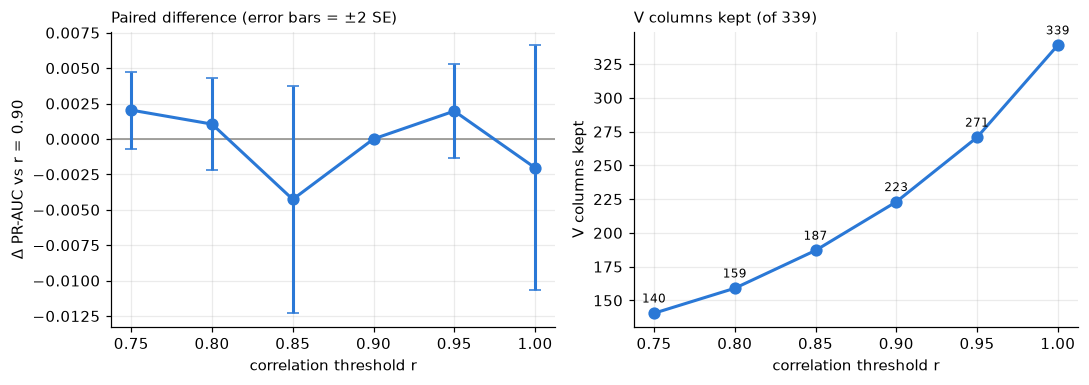

In [8]:
if len(results):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    ax = axes[0]
    x = results.index.to_numpy()
    se = results["SE of Δ"].fillna(0).to_numpy()
    ax.axhline(0, color=GREY, lw=1)
    ax.errorbar(x, results["Δ vs r=0.90"], yerr=2 * se, color=BLUE, lw=2, marker="o", ms=7, capsize=4)
    ax.set_xlabel("correlation threshold r")
    ax.set_ylabel("Δ PR-AUC vs r = 0.90")
    ax.set_title("Paired difference (error bars = ±2 SE)", loc="left", fontsize=10)

    ax = axes[1]
    ax.plot(x, results["V kept (avg over folds)"], color=BLUE, lw=2, marker="o", ms=7)
    for xi, n in zip(x, results["V kept (avg over folds)"]):
        ax.annotate(f"{n:.0f}", (xi, n), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_xlabel("correlation threshold r")
    ax.set_ylabel("V columns kept")
    ax.set_title("V columns kept (of 339)", loc="left", fontsize=10)
    fig.tight_layout()
    plt.show()

In [9]:
# per-fold PR-AUC (mean over seeds), to see whether any threshold helps only in some months
sw["fold"] = sw["fold"].astype(int)
per_fold = sw.groupby(["v_threshold", "fold"])["pr_auc"].mean().unstack().add_prefix("fold ")
per_fold.round(4)

fold,fold 1,fold 2,fold 3,fold 4
v_threshold,,,,
0.75,0.5711,0.5997,0.5746,0.6326
0.80,0.5707,0.5968,0.5724,0.6342
0.85,0.5686,0.5964,0.5564,0.6315
0.90,0.5673,0.6009,0.5714,0.6302
0.95,0.5686,0.5986,0.5764,0.6341
1.00,0.5688,0.5990,0.5592,0.6349


## 7. How to read this

- If every Δ sits within ±2 SE of zero, XGBoost doesn't care where r is in this range. Then the lowest r with no
  loss is the practical pick: fewer columns, faster fits, and SHAP credit isn't split between near-identical twins.
- If low thresholds lose clearly, pruning that hard throws away signal, and r = 0.90 (or higher) is safer.
- If r = 1.00 wins clearly, the pruned columns carry something the kept ones don't.

XGBoost is the model least bothered by correlated columns. The shared V list also feeds logistic regression and
the MLP, which are more sensitive, so the group decision should take those into account too.